# Simple ALM hedging model: RILA, FIA, and IUL

**Illustrative model with synthetic inputs.** One year, one index, $100 of account value per
product, closed-form Black-Scholes with flat rate, dividend yield, and volatility. No Monte
Carlo, no optimizer, no policyholder behavior. Everything here comes from `simple_model.py`
in this folder, which deliberately does not import from the full framework under
`src/alm_hedging`, so the notebook can be read and run on its own. The one-page PDF built by
`build_report.py` uses the same `run_simple_model()` call, so the two reconcile exactly.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import simple_model as sm

plt.rcParams.update({"figure.dpi": 110, "text.parse_math": False})
results = sm.run_simple_model()
m = results.market

## 1. Market and product assumptions

An indexed insurance product credits interest through an option package on an equity index.
For ALM, the first question is simply *what did we promise?* Writing each design down as
vanilla option legs makes the promise explicit, lets a single pricing model value all three
products, and makes the Greeks in later sections additive across products.

In [2]:
print(
    f"Index {m.spot:.0f}, 1y rate {m.rate:.1%}, dividend {m.dividend:.1%}, vol {m.vol:.0%}, maturity {m.maturity:.0f}y"
)
pd.DataFrame(
    [
        {
            "Product": p.name,
            "Design": p.description,
            "Account value": p.account_value,
            "Legs": ", ".join(
                f"{leg.quantity:+.0f} {leg.kind} @ {leg.strike:.1f}" for leg in p.legs
            ),
        }
        for p in results.products
    ]
).set_index("Product")

Index 100, 1y rate 4.0%, dividend 1.5%, vol 19%, maturity 1y


,Design,Account value,Legs
Product,,,
RILA,"10% buffer, 18.0% cap: long ATM call, short 1....",100.0,"+1 call @ 100.0, -1 call @ 118.0, -1 put @ 90.0"
FIA,"0% floor, 9.5% cap: long ATM call, short 1.095...",100.0,"+1 call @ 100.0, -1 call @ 109.5"
IUL,"0% floor, 11.0% cap on one year of account val...",100.0,"+1 call @ 100.0, -1 call @ 111.0"


## 2. Payoff diagrams

The payoff at maturity is the liability the insurer must fund as a function of the index.
The FIA and IUL call spreads are floored at zero and capped, so the insurer's exposure is
one-sided and bounded. The RILA is different: the policyholder absorbs losses beyond the 10%
buffer, which means the insurer is *long* a put struck at 90 on the policyholder's behalf, and
that short-put-to-the-policyholder is what pays for the much higher cap.

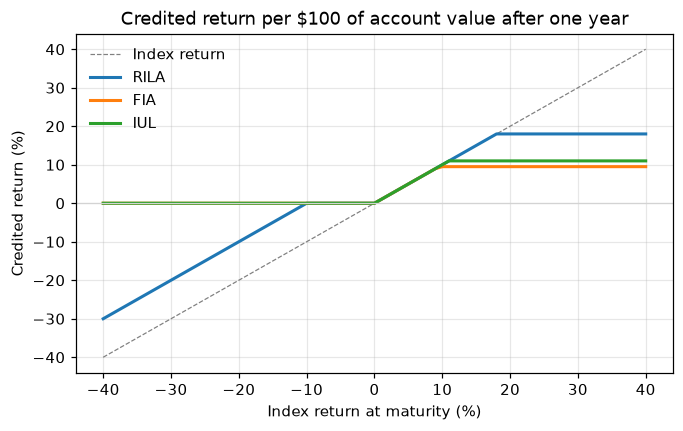

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
idx = [100 * (x - 1) for x in results.payoff_grid]
ax.plot(idx, idx, ls="--", color="grey", lw=0.8, label="Index return")
for name, credited in results.payoffs.items():
    ax.plot(idx, [100 * c for c in credited], lw=2, label=name)
ax.axhline(0, color="lightgrey", lw=0.8)
ax.set_xlabel("Index return at maturity (%)")
ax.set_ylabel("Credited return (%)")
ax.set_title("Credited return per $100 of account value after one year")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

## 3. Pricing and option-leg decomposition

The PV of the option package is what the insurer must spend (the *option budget*) to back the
crediting promise, and it has to be covered by the spread earned on the general account. Pricing
leg by leg shows where the cost comes from: every product starts with the same at-the-money
call, and the short legs are what bring the cost down to an affordable level.

In [4]:
rows = []
for v in results.valuations:
    for leg in v.legs:
        rows.append(
            {
                "Product": v.product.name,
                "Leg": leg.label,
                "Strike": leg.strike,
                "Qty": leg.quantity,
                "PV": leg.greeks.price,
            }
        )
    rows.append(
        {
            "Product": v.product.name,
            "Leg": "Total",
            "Strike": None,
            "Qty": None,
            "PV": v.pv,
        }
    )
leg_table = pd.DataFrame(rows).set_index(["Product", "Leg"])
leg_table.round(4)

Strike  Qty      PV
Product Leg                                         
RILA    Long ATM call             100.0  1.0  8.6434
        Short 1.180 call (cap)    118.0 -1.0 -2.6747
        Short 0.90 put (buffer)    90.0 -1.0 -2.5585
        Total                       NaN  NaN  3.4102
FIA     Long ATM call             100.0  1.0  8.6434
        Short 1.095 call (cap)    109.5 -1.0 -4.8171
        Total                       NaN  NaN  3.8263
IUL     Long ATM call             100.0  1.0  8.6434
        Short 1.11 call (cap)     111.0 -1.0 -4.3606
        Total                       NaN  NaN  4.2827

## 4. Greeks

Greeks tell the hedger how the liability moves before anything is traded. Delta is the
first-order index exposure that futures can neutralise; gamma, vega, and rho are the exposures
that a futures hedge leaves behind. Because the products are sums of vanilla legs, the
portfolio Greeks are just the sums of the product Greeks, which is what makes a single
portfolio-level hedge possible.

In [5]:
greeks = pd.DataFrame(
    {v.product.name: sm.scaled_greeks(v.greeks) for v in results.valuations}
)
greeks["Portfolio"] = pd.Series(sm.scaled_greeks(results.portfolio))
greeks.round(4)

,RILA,FIA,IUL,Portfolio
PV,3.4102,3.8263,4.2827,11.5192
Delta (per index pt),0.5392,0.1859,0.2129,0.9381
Gamma (per index pt^2),-0.0119,0.0001,0.0005,-0.0112
Vega (per vol pt),-0.2259,0.0022,0.0100,-0.2137
Rho (per bp),0.0051,0.0015,0.0017,0.0082
Theta (per day),0.0026,-0.0009,-0.0012,0.0004


## 5. Cap rate versus option budget

The cap is the main lever product management can pull each year, and this curve is how it is
set: a given option budget buys a given cap, and when volatility or rates move, the cap must
move too. The chart shows the PV of each design as a function of its cap, and the solved cap
that the default budget affords for each product.

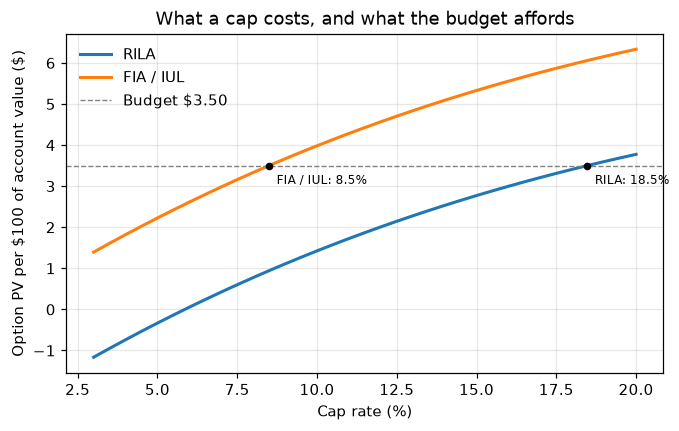

,Cap for budget
RILA,18.47%
FIA,8.50%
IUL,8.50%


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
# FIA and IUL share the call-spread shape, so their curves coincide; draw each distinct curve once.
distinct: dict[tuple[float, ...], list[str]] = {}
for name, curve in results.budget_curve.items():
    distinct.setdefault(tuple(round(pv, 10) for _, pv in curve), []).append(name)
caps = [100 * cap for cap, _ in next(iter(results.budget_curve.values()))]
for pvs, names in distinct.items():
    ax.plot(caps, pvs, lw=2, label=" / ".join(names))
ax.axhline(
    results.option_budget,
    color="grey",
    ls="--",
    lw=0.9,
    label=f"Budget ${results.option_budget:.2f}",
)
solved: dict[float, list[str]] = {}
for name, cap in results.solved_caps.items():
    solved.setdefault(round(cap, 8), []).append(name)
for cap, names in solved.items():
    ax.plot(100 * cap, results.option_budget, "o", color="black", ms=4)
    ax.annotate(
        f"{' / '.join(names)}: {cap:.1%}",
        (100 * cap, results.option_budget),
        textcoords="offset points",
        xytext=(5, -12),
        fontsize=8,
    )
ax.set_xlabel("Cap rate (%)")
ax.set_ylabel("Option PV per $100 of account value ($)")
ax.set_title("What a cap costs, and what the budget affords")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame({"Cap for budget": results.solved_caps}).style.format("{:.2%}")

## 6. Delta hedge and stress test

A delta hedge with index futures is the simplest and cheapest way to remove the first-order
equity exposure. Full revaluation (repricing every leg under each shock rather than relying on
Greeks) is the honest test of whether the hedge works, because it captures the gamma and vega
that the futures do not cover. The table shows liability PV and insurer P&L before and after
the hedge for the index, volatility, and rate shocks.

In [7]:
h = results.hedge
print(
    f"Liability delta {h.liability_delta:.4f} per index point -> buy {h.futures_units:.4f} index futures units"
)
print(
    f"Residual gamma {h.residual_gamma:+.4f} per pt^2, vega {h.residual_vega * 0.01:+.4f} per vol pt, rho {h.residual_rho * 1e-4:+.4f} per bp"
)
stress = pd.DataFrame(
    [
        {
            "Scenario": r.scenario,
            "Liability PV": r.liability_pv,
            "Unhedged P&L": r.unhedged_pnl,
            "Futures P&L": r.hedge_pnl,
            "Hedged P&L": r.hedged_pnl,
        }
        for r in results.stress
    ]
).set_index("Scenario")
stress.loc["Range (max - min)"] = [
    None,
    results.unhedged_range,
    None,
    results.hedged_range,
]
stress.round(2)

Liability delta 0.9381 per index point -> buy 0.9149 index futures units
Residual gamma +0.0112 per pt^2, vega +0.2137 per vol pt, rho -0.0082 per bp


,Liability PV,Unhedged P&L,Futures P&L,Hedged P&L
Scenario,,,,
Index -20%,-8.10,19.62,-18.76,0.86
Index -10%,1.77,9.75,-9.38,0.37
Index +10%,20.16,-8.64,9.38,0.74
Index +20%,26.84,-15.32,18.76,3.44
Vol +5 pts,10.24,1.28,0.00,1.28
Rates +50 bp,11.93,-0.41,0.47,0.06
Rates -50 bp,11.11,0.41,-0.47,-0.05
Range (max - min),NaN,34.94,NaN,3.50


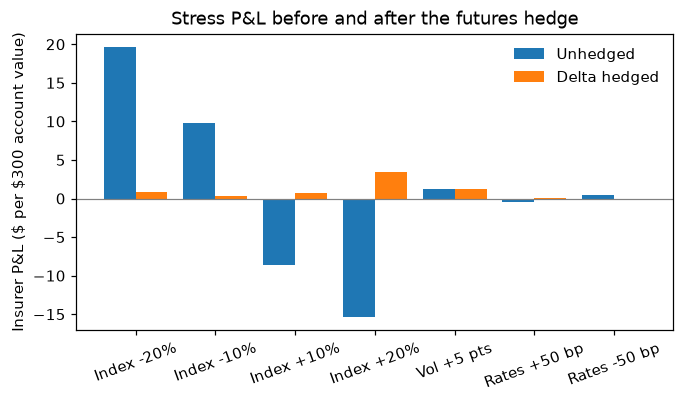

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
x = range(len(results.stress))
ax.bar(
    [i - 0.2 for i in x],
    [r.unhedged_pnl for r in results.stress],
    width=0.4,
    label="Unhedged",
)
ax.bar(
    [i + 0.2 for i in x],
    [r.hedged_pnl for r in results.stress],
    width=0.4,
    label="Delta hedged",
)
ax.set_xticks(list(x), [r.scenario for r in results.stress], rotation=20)
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Insurer P&L ($ per $300 account value)")
ax.set_title("Stress P&L before and after the futures hedge")
ax.legend(frameon=False)
plt.show()

### Recommendation

In [9]:
import textwrap

print(textwrap.fill(sm.recommendation(results), 100))

Buy 0.915 index futures units (notional about $91 against $300 of account value) to offset the
liability delta of 0.938 per index point. Full revaluation shows the stress P&L range shrinking from
$34.94 to $3.50. The hedge is linear, so residual risks remain: the insurer is long gamma (+0.0112
per index point squared, so the hedged book gains on large moves in either direction; worst hedged
scenario is Rates -50 bp at $-0.05), long vega (+0.214 per vol point; a +5 pt vol shock adds $1.28),
and rho of -0.0082 per basis point, which the futures roll partly offsets. Rebalance the futures as
delta drifts with the index and with time, and revisit the hedge if the gamma, vega, or rate
residuals move outside the risk budget. Illustrative model with synthetic inputs.


---
*Illustrative model with synthetic inputs. Not investment advice and not a production valuation
system. The full framework under `src/alm_hedging` adds term structures, volatility surfaces,
Monte Carlo, multi-Greek and constrained hedge optimisation, and policyholder behavior.*